In [1]:
# ============================================
# Cell 0: 分析設定
# ============================================

# ============================================
# 🎯 自選股清單
# ============================================
WATCHLIST = [
    #電子商貿及互聯網服務
    "0700.HK", "1024.HK", "3690.HK", "9988.HK",
    #多元化保險
    "1299.HK",
    #人壽與健康保險
    "2318.HK", "2628.HK",
    #半導體產品及設備
    "0981.HK", "1347.HK",
    #綜合性銀行
    "0005.HK", "0939.HK", "1398.HK",
    #電腦硬件
    "0992.HK",
    #智能手機
    "1810.HK",
    #生物科技
    "1801.HK", "2269.HK",
    #綜合性石油與天然氣企業
    "0883.HK",
    #房地產開發
    "1109.HK",
    #電訊服務
    "0941.HK",
    #汽車製造商
    "1211.HK", "0175.HK",
    #黃金與貴金屬
    "2899.HK",
    #鋁
    "1378.HK",
    #其它綜合性金融服務
    "0388.HK"
]

# ============================================
# 資料庫設定
# ============================================
DB_PATH = "hk_trading.db"
FULL_DOWNLOAD_YEARS = 10
MAX_WORKERS = 5

# ============================================
# 回測設定
# ============================================
BACKTEST_CONFIG = {
    "initial_capital": 1_000_000,
    "commission": 0.001,
    "slippage": 0.001,
    "backtest_start": "2018-01-01",
    "backtest_end": None,
}

# ============================================
# 顯示摘要
# ============================================
print("="*70)
print("⚙️ 分析設定")
print("="*70)
print(f"   自選股數量: {len(WATCHLIST)}")
print(f"   資料庫: {DB_PATH}")
print(f"   回測期間: {BACKTEST_CONFIG['backtest_start']} ~ {BACKTEST_CONFIG['backtest_end'] or '至今'}")
print(f"   自選股: {WATCHLIST}")
print("="*70)

⚙️ 分析設定
   自選股數量: 24
   資料庫: hk_trading.db
   回測期間: 2018-01-01 ~ 至今
   自選股: ['0700.HK', '1024.HK', '3690.HK', '9988.HK', '1299.HK', '2318.HK', '2628.HK', '0981.HK', '1347.HK', '0005.HK', '0939.HK', '1398.HK', '0992.HK', '1810.HK', '1801.HK', '2269.HK', '0883.HK', '1109.HK', '0941.HK', '1211.HK', '0175.HK', '2899.HK', '1378.HK', '0388.HK']


In [2]:
# ============================================
# Cell 1: 導入模組
# ============================================

import sys
import warnings
from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 自動重新載入
%load_ext autoreload
%autoreload 2

sys.path.append(str(Path.cwd()))

# 導入模組
from data_engine import MarketDatabase
from alpha_library import calculate_rsi, calculate_macd, calculate_bollinger_bands
from strategy import (
    GoldenCrossStrategy, MACDStrategy, RSIStrategy,
    BollingerBandsStrategy, BreakoutStrategy,
    MultiIndicatorStrategy, TrendFilterStrategy,
)
from backtester import Backtester, PortfolioBacktester

# 顯示設定
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
warnings.filterwarnings('ignore', category=FutureWarning)

print(f"📅 執行時間: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"📊 自選股數量: {len(WATCHLIST)}")
print("✅ 導入完成")

📅 執行時間: 2026-10-19 15:02:14
📊 自選股數量: 24
✅ 導入完成


In [3]:
# ============================================
# Cell 2: 同步數據到資料庫
# ============================================

from data_engine import MarketDatabase

# 建立資料庫連線
db = MarketDatabase(db_path=DB_PATH)

print("\n" + "="*70)
print("💾 同步自選股數據")
print("="*70)

# 同步所有自選股
sync_stats = db.sync_data(
    tickers=WATCHLIST,
    max_workers=MAX_WORKERS,
    full_download_years=FULL_DOWNLOAD_YEARS,
    skip_recent_days=7,
)

print(f"\n📊 同步結果:")
print(f"   成功: {sync_stats.get('updated', 0)}")
print(f"   跳過: {sync_stats.get('skipped', 0)}")
print(f"   失敗: {sync_stats.get('failed', 0)}")

# 顯示資料庫摘要
print(f"\n📋 資料庫摘要:")
summary = db.get_data_summary()
print(summary)

2026-10-19 15:02:14 - INFO - ✅ MarketDatabase 初始化: hk_trading.db
2026-10-19 15:02:14 - INFO - 🔄 開始同步 24 支股票 (並發: 5)



💾 同步自選股數據


2026-10-19 15:02:14 - INFO - ✅ [9988.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [3690.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [1024.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [0700.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [1299.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [0981.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [1347.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [2318.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [2628.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [0005.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [1810.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [0939.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [1398.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [0992.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [2269.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [1801.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [0883.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [1109.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [0941.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [0175.HK] 新增 1 筆
2026-10-19 15:02:14 - INFO - ✅ [1211.HK]


📊 同步結果:
   成功: 24
   跳過: 0
   失敗: 0

📋 資料庫摘要:
     ticker  days  start_date    end_date
0   0005.HK  2466  2016-10-11  2026-10-16
1   0175.HK  2462  2016-10-17  2026-10-16
2   0388.HK  2459  2016-10-21  2026-10-16
3   0700.HK  2466  2016-10-11  2026-10-16
4   0883.HK  2466  2016-10-11  2026-10-16
5   0939.HK  2466  2016-10-11  2026-10-16
6   0941.HK  2466  2016-10-11  2026-10-16
7   0981.HK  2466  2016-10-11  2026-10-16
8   0992.HK  2466  2016-10-11  2026-10-16
9   1024.HK  1398  2021-02-05  2026-10-16
10  1109.HK  2466  2016-10-11  2026-10-16
11  1211.HK  2466  2016-10-11  2026-10-16
12  1299.HK  2466  2016-10-11  2026-10-16
13  1347.HK  2466  2016-10-11  2026-10-16
14  1378.HK  2459  2016-10-21  2026-10-16
15  1398.HK  2466  2016-10-11  2026-10-16
16  1801.HK  1958  2018-10-31  2026-10-16
17  1810.HK  2037  2018-07-09  2026-10-16
18  2269.HK  2302  2017-06-13  2026-10-16
19  2318.HK  2466  2016-10-11  2026-10-16
20  2618.HK  1324  2021-05-28  2026-10-15
21  2628.HK  2462  2016-10-17

In [4]:
# ============================================
# Cell 3: 單股回測
# ============================================

from backtester import Backtester

# ============================================
# 3.1 選擇回測標的
# ============================================
BACKTEST_TICKER = WATCHLIST[1]   # 預設第一支
STRATEGY_NAME = "bollinger"      # 預設 Bollinger

STRATEGY_PARAMS = {
    "golden_cross": {"fast_period": 20, "slow_period": 60},
    "macd": {"fast": 12, "slow": 26, "signal": 9},
    "rsi": {"period": 14, "oversold": 30, "overbought": 70},
    "bollinger": {"period": 20, "std_dev": 2.0},
    "breakout": {"lookback": 20},
}

print("\n" + "="*70)
print(f"🎯 單股回測: {BACKTEST_TICKER}")
print("="*70)

# ============================================
# 3.2 取得數據
# ============================================
df = db.get_ohlcv(
    BACKTEST_TICKER,
    start_date=BACKTEST_CONFIG["backtest_start"],
    end_date=BACKTEST_CONFIG["backtest_end"] or datetime.now().strftime("%Y-%m-%d"),
)

if df.empty:
    raise RuntimeError(f"❌ {BACKTEST_TICKER} 無數據")

print(f"   ✅ 取得 {len(df)} 筆數據")
print(f"   期間: {df.index[0].date()} ~ {df.index[-1].date()}")
print(f"   起始價: {df['close'].iloc[0]:.2f}")
print(f"   結束價: {df['close'].iloc[-1]:.2f}")

# ============================================
# 3.3 建立策略
# ============================================
from strategy import get_strategy

strategy = get_strategy(
    STRATEGY_NAME,
    **STRATEGY_PARAMS[STRATEGY_NAME],
)

print(f"\n🎯 策略: {strategy}")

# ============================================
# 3.4 執行回測
# ============================================
backtester = Backtester(
    initial_capital=BACKTEST_CONFIG["initial_capital"],
    commission=BACKTEST_CONFIG["commission"],
    slippage=BACKTEST_CONFIG["slippage"],
)

result = backtester.run(df, strategy)

# ============================================
# 3.5 顯示回測報告
# ============================================
print(result.summary())

# ============================================
# 3.6 顯示交易記錄
# ============================================
print("\n📋 完整交易記錄:")
print("-" * 100)

if result.trades:
    print(f"{'日期':<12} {'動作':<6} {'價格':>10} {'股數':>10} {'損益':>15}")
    print("-" * 100)
    for t in result.trades:
        pnl_str = f"{t.pnl:+,.2f}" if t.pnl is not None else "-"
        date_str = t.date.strftime('%Y-%m-%d') if hasattr(t.date, 'strftime') else str(t.date)
        print(f"{date_str:<12} {t.action:<6} {t.price:>10.2f} "
              f"{t.shares:>10,} {pnl_str:>15}")


🎯 單股回測: 1024.HK
   ✅ 取得 1398 筆數據
   期間: 2021-02-05 ~ 2026-10-16
   起始價: 300.00
   結束價: 29.30

🎯 策略: BollingerBandsStrategy(period=20, std_dev=2.0)
📊 回測報告: Bollinger(20,2.0)

💰 資金表現:
   初始資金:    1,000,000.00
   最終資金:      175,814.03
   總報酬:           -82.42%
   年化報酬:         -26.90%

📈 風險指標:
   年化波動:          44.76%
   Sharpe:             -0.60
   Sortino:            -0.65
   最大回撤:         -84.42%
   Calmar:             -0.32

📉 交易統計:
   總交易數:              27
   勝率:              38.46%
   平均獲利:          13.19%
   平均虧損:         -20.36%
   盈虧比:              0.40


📋 完整交易記錄:
----------------------------------------------------------------------------------------------------
日期           動作             價格         股數              損益
----------------------------------------------------------------------------------------------------
2021-06-22   BUY        187.99      5,314               -
2021-09-07   SELL       101.80      5,314     -458,553.03
2021-11-26   BUY         90.09      5,992    

2026-10-19 15:02:14 - WARNING - findfont: Failed to find font weight bold, now using 400.


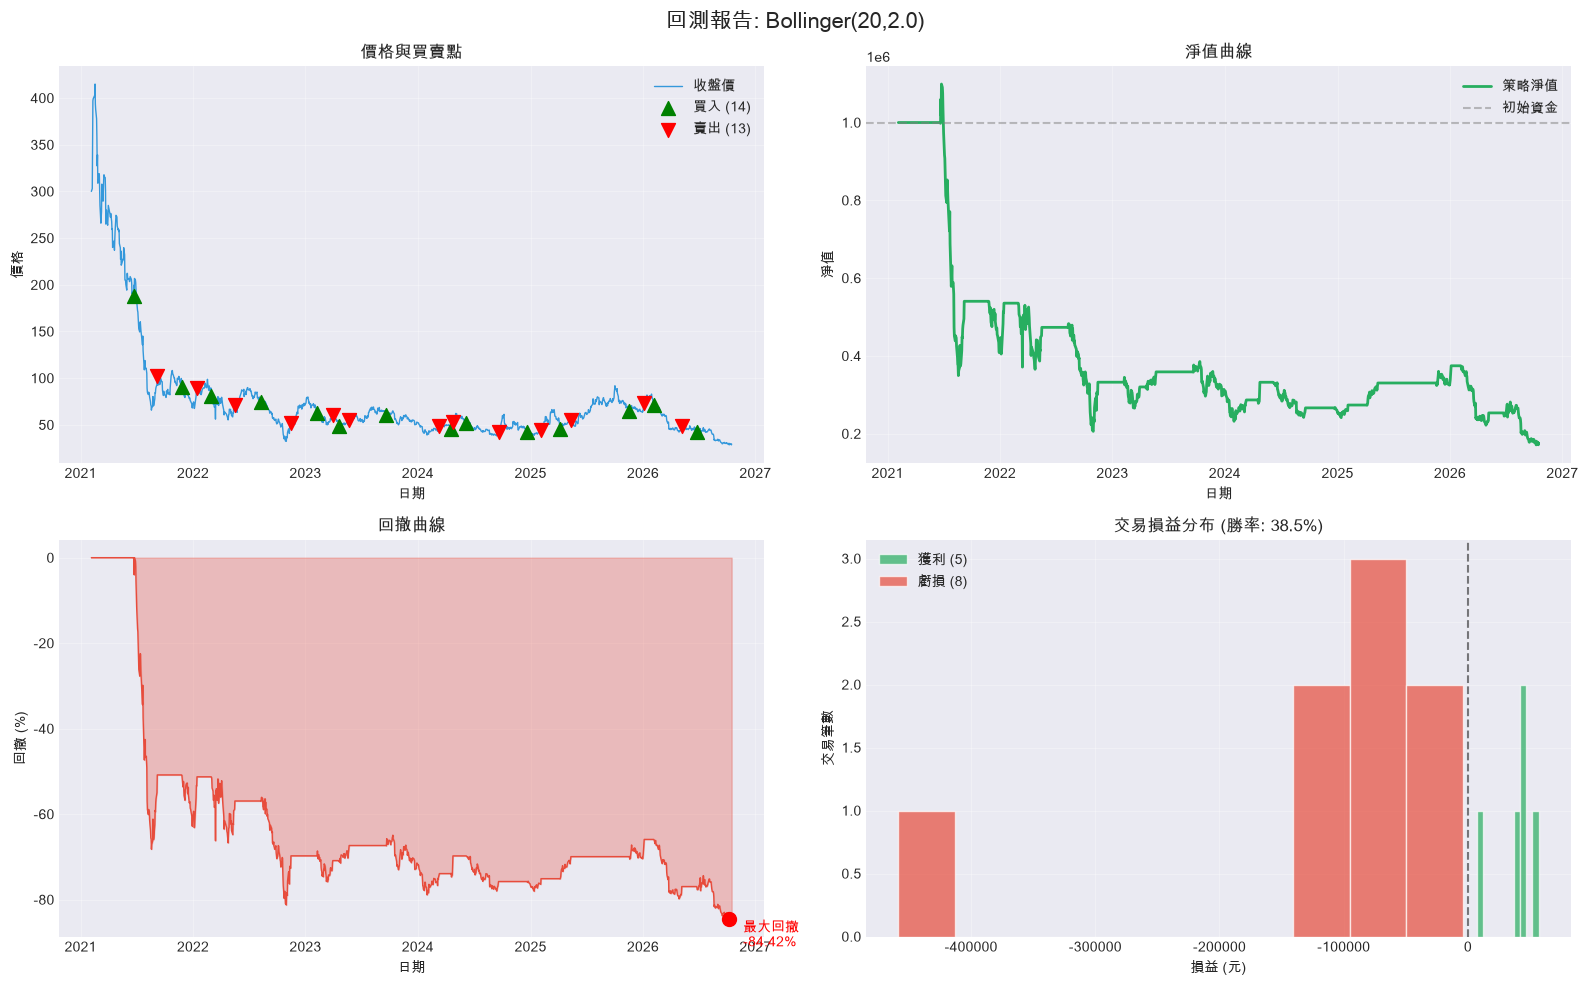

✅ 視覺化已保存: backtest_visualization.png


In [5]:
# ============================================
# Cell 4: 回測視覺化
# ============================================

# 中文字型設定
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager as fm
import seaborn as sns

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

FONT_PATH = "/Library/Fonts/Arial Unicode.ttf"
fm.fontManager.addfont(FONT_PATH)
prop = FontProperties(fname=FONT_PATH)

plt.rcParams['font.sans-serif'] = [prop.get_name()]
plt.rcParams['axes.unicode_minus'] = False

# ============================================
# 4 合 1 圖表
# ============================================
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(f'回測報告: {strategy.name}', fontsize=16, fontweight='bold')

# ---------- 圖 1：價格 + 買賣點 ----------
ax = axes[0, 0]
ax.plot(df.index, df['close'], color='#3498db', linewidth=1, label='收盤價')

buy_trades = [t for t in result.trades if t.action == 'BUY']
sell_trades = [t for t in result.trades if t.action == 'SELL']

if buy_trades:
    ax.scatter([t.date for t in buy_trades], [t.price for t in buy_trades],
               color='green', marker='^', s=100, label=f'買入 ({len(buy_trades)})', zorder=5)
if sell_trades:
    ax.scatter([t.date for t in sell_trades], [t.price for t in sell_trades],
               color='red', marker='v', s=100, label=f'賣出 ({len(sell_trades)})', zorder=5)

ax.set_xlabel('日期')
ax.set_ylabel('價格')
ax.set_title('價格與買賣點')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)

# ---------- 圖 2：淨值曲線 ----------
ax = axes[0, 1]
ax.plot(result.equity.index, result.equity.values,
        color='#27ae60', linewidth=2, label='策略淨值')
ax.axhline(y=BACKTEST_CONFIG["initial_capital"],
           color='gray', linestyle='--', alpha=0.5, label='初始資金')
ax.set_xlabel('日期')
ax.set_ylabel('淨值')
ax.set_title('淨值曲線')
ax.legend(loc='best')
ax.grid(True, alpha=0.3)

# ---------- 圖 3：回撤曲線 ----------
ax = axes[1, 0]
rolling_max = result.equity.cummax()
drawdown = (result.equity / rolling_max - 1) * 100
ax.fill_between(drawdown.index, drawdown.values, 0, color='#e74c3c', alpha=0.3)
ax.plot(drawdown.index, drawdown.values, color='#e74c3c', linewidth=1)

max_dd = drawdown.min()
max_dd_date = drawdown.idxmin()
ax.scatter([max_dd_date], [max_dd], color='red', s=100, zorder=5)
ax.annotate(f'最大回撤\n{max_dd:.2f}%',
            xy=(max_dd_date, max_dd),
            xytext=(10, -20), textcoords='offset points',
            fontsize=10, color='red')

ax.set_xlabel('日期')
ax.set_ylabel('回撤 (%)')
ax.set_title('回撤曲線')
ax.grid(True, alpha=0.3)

# ---------- 圖 4：交易損益分布 ----------
ax = axes[1, 1]
sell_pnls = [t.pnl for t in result.trades if t.action == 'SELL' and t.pnl is not None]

if sell_pnls:
    wins = [p for p in sell_pnls if p > 0]
    losses = [p for p in sell_pnls if p < 0]
    
    if wins:
        ax.hist(wins, bins=10, color='#27ae60', alpha=0.7,
                label=f'獲利 ({len(wins)})', edgecolor='white')
    if losses:
        ax.hist(losses, bins=10, color='#e74c3c', alpha=0.7,
                label=f'虧損 ({len(losses)})', edgecolor='white')
    
    ax.axvline(x=0, color='black', linestyle='--', alpha=0.5)
    total = len(sell_pnls)
    win_rate = len(wins) / total * 100 if total > 0 else 0
    ax.set_title(f'交易損益分布 (勝率: {win_rate:.1f}%)')
    ax.legend(loc='best')

ax.set_xlabel('損益 (元)')
ax.set_ylabel('交易筆數')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('backtest_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ 視覺化已保存: backtest_visualization.png")

In [6]:
# ============================================
# Cell 5: 多策略比較
# ============================================

print("\n" + "="*70)
print("📊 多策略比較")
print("="*70)

# ============================================
# 5.1 定義策略
# ============================================
strategies_to_test = [
    # ⭐⭐⭐ 核心（4 個）
    TrendFilterStrategy(RSIStrategy(14, 30, 70), 200),
    BollingerBandsStrategy(20, 2.0),
    TrendFilterStrategy(BollingerBandsStrategy(20, 2.0), 200),
    MultiIndicatorStrategy([BollingerBandsStrategy(20, 2.0), RSIStrategy(14, 30, 70)], mode="and"),
    
    # ⭐⭐ 常用（4 個）
    RSIStrategy(14, 30, 70),
    GoldenCrossStrategy(20, 60),
    TrendFilterStrategy(GoldenCrossStrategy(20, 60), 200),
    GoldenCrossStrategy(10, 30),
    
    # ⭐ 專精（3 個）
    BreakoutStrategy(20),
    MACDStrategy(),
    TrendFilterStrategy(GoldenCrossStrategy(10, 30), 200),
]

# ============================================
# 5.2 執行回測
# ============================================
comparison_results = []

for strat in strategies_to_test:
    try:
        res = backtester.run(df, strat)
        comparison_results.append({
            'strategy': strat.name,
            'total_return': res.metrics['total_return'],
            'annual_return': res.metrics['annual_return'],
            'sharpe': res.metrics['sharpe_ratio'],
            'max_drawdown': res.metrics['max_drawdown'],
            'trades': res.metrics['total_trades'],
            'win_rate': res.metrics['win_rate'],
        })
    except Exception as e:
        print(f"   ⚠️ {strat.name} 失敗: {e}")

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values('sharpe', ascending=False)

# ============================================
# 5.3 顯示結果
# ============================================
print(f"\n📊 策略比較（按 Sharpe 排序）:")
print("-" * 110)
print(f"{'策略':<40} {'總報酬':>10} {'年化':>10} {'Sharpe':>8} "
      f"{'回撤':>10} {'交易':>6} {'勝率':>8}")
print("-" * 110)

for _, row in comparison_df.iterrows():
    print(f"{row['strategy']:<40} "
          f"{row['total_return']*100:>9.2f}% "
          f"{row['annual_return']*100:>9.2f}% "
          f"{row['sharpe']:>8.2f} "
          f"{row['max_drawdown']*100:>9.2f}% "
          f"{row['trades']:>6.0f} "
          f"{row['win_rate']*100:>7.2f}%")

# 最佳策略
best = comparison_df.iloc[0]
print(f"\n🏆 最佳策略: {best['strategy']}")
print(f"   Sharpe: {best['sharpe']:.2f}")
print(f"   總報酬: {best['total_return']*100:.2f}%")


📊 多策略比較

📊 策略比較（按 Sharpe 排序）:
--------------------------------------------------------------------------------------------------------------
策略                                              總報酬         年化   Sharpe         回撤     交易       勝率
--------------------------------------------------------------------------------------------------------------
TrendFilter(RSI(14,30,70),200)                0.00%      0.00%     0.00      0.00%      0    0.00%
Breakout(20)                                 -1.68%     -0.31%    -0.01    -35.24%     26   53.85%
TrendFilter(GoldenCross(10,30),200)          -6.42%     -1.19%    -0.07    -36.10%     20   20.00%
MACD(12,26,9)                               -35.45%     -7.59%    -0.18    -60.68%     95   34.04%
GoldenCross(10,30)                          -42.54%     -9.50%    -0.28    -47.09%     48   29.17%
TrendFilter(GoldenCross(20,60),200)         -40.60%     -8.96%    -0.33    -46.51%     12   33.33%
RSI(14,30,70)                               -65.75%   


📊 多股票測試（24 支股票 × 11 個策略）
   總計: 264 次回測


2026-10-19 15:02:24 - WARNING - findfont: Failed to find font weight bold, now using 400.



✅ 完成 264 次回測（失敗 0 次）

🏆 每支股票的最佳策略:
------------------------------------------------------------------------------------------
2269.HK      TrendFilter(RSI(14,30,70),200)                Sharpe=  1.32  報酬= 394.41%
1810.HK      TrendFilter(RSI(14,30,70),200)                Sharpe=  1.05  報酬= 215.63%
2899.HK      Bollinger(20,2.0)                             Sharpe=  1.03  報酬= 737.81%
3690.HK      TrendFilter(GoldenCross(10,30),200)           Sharpe=  0.97  報酬= 529.03%
0005.HK      TrendFilter(Bollinger(20,2.0),200)            Sharpe=  0.78  報酬=  89.51%
1378.HK      GoldenCross(20,60)                            Sharpe=  0.77  報酬= 682.50%
1109.HK      Bollinger(20,2.0)                             Sharpe=  0.76  報酬= 418.06%
0388.HK      TrendFilter(RSI(14,30,70),200)                Sharpe=  0.73  報酬=  50.93%
0939.HK      TrendFilter(RSI(14,30,70),200)                Sharpe=  0.73  報酬=  33.26%
1801.HK      GoldenCross(10,30)                            Sharpe=  0.71  報酬= 600.58%
0992.HK      

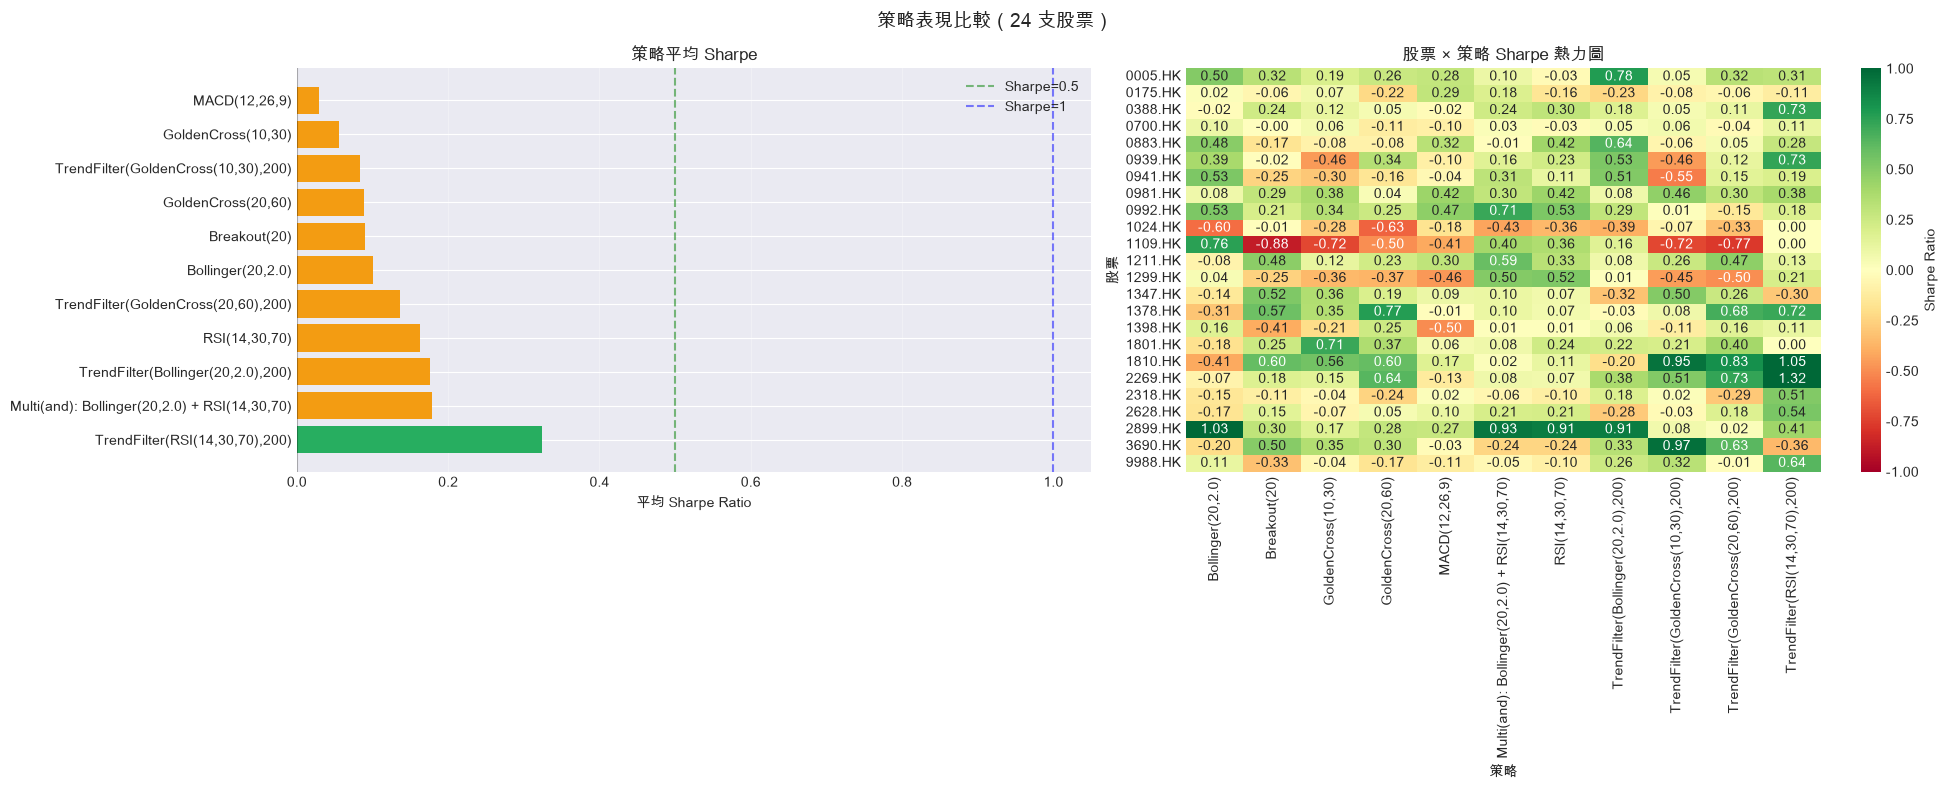


✅ 結果已導出: outputs/watchlist_backtest_20261019.csv

🏆 每支股票 Top 3 策略

0005.HK:
   排名   策略                                              Sharpe         報酬         回撤     交易       勝率
   ----------------------------------------------------------------------------------------------------
   🥇 1  TrendFilter(Bollinger(20,2.0),200)                0.78     89.51%    -15.83%     27    84.6% ✅
   🥈 2  Bollinger(20,2.0)                                 0.50    104.80%    -50.61%     55    70.4% ✅
   🥉 3  TrendFilter(GoldenCross(20,60),200)               0.32     48.31%    -33.82%     22    54.5% ✅

0175.HK:
   排名   策略                                              Sharpe         報酬         回撤     交易       勝率
   ----------------------------------------------------------------------------------------------------
   🥇 1  MACD(12,26,9)                                     0.29    132.20%    -48.58%    151    38.7% ⚠️
   🥈 2  Multi(and): Bollinger(20,2.0) + RSI(14,30,70)     0.18     59.61%    -62.84%     1

In [7]:
# ============================================
# Cell 6: 多股票 × 多策略測試
# ============================================

# ============================================
# 6.0 依賴檢查
# ============================================
from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if 'WATCHLIST' not in dir():
    raise RuntimeError("❌ 請先執行 Cell 0（定義自選股）")
if 'db' not in dir():
    raise RuntimeError("❌ 請先執行 Cell 2（建立資料庫）")
if 'backtester' not in dir():
    raise RuntimeError("❌ 請先執行 Cell 3（建立回測器）")
if 'strategies_to_test' not in dir():
    raise RuntimeError("❌ 請先執行 Cell 5（定義策略清單）")

print("\n" + "="*70)
print(f"📊 多股票測試（{len(WATCHLIST)} 支股票 × {len(strategies_to_test)} 個策略）")
print(f"   總計: {len(WATCHLIST) * len(strategies_to_test)} 次回測")
print("="*70)

# ============================================
# 6.1 執行回測
# ============================================
all_results = []
failed_count = 0

for ticker in WATCHLIST:
    # 取得數據
    df_t = db.get_ohlcv(
        ticker,
        start_date=BACKTEST_CONFIG["backtest_start"],
        end_date=BACKTEST_CONFIG.get("backtest_end") or datetime.now().strftime("%Y-%m-%d"),
    )
    if df_t.empty:
        print(f"   ⚠️ {ticker}: 無數據")
        continue
    
    for strategy in strategies_to_test:
        try:
            result = backtester.run(df_t, strategy)
            all_results.append({
                'ticker': ticker,
                'strategy': strategy.name,
                'total_return': result.metrics['total_return'],
                'annual_return': result.metrics['annual_return'],
                'sharpe': result.metrics['sharpe_ratio'],
                'max_drawdown': result.metrics['max_drawdown'],
                'win_rate': result.metrics['win_rate'],
                'trades': result.metrics['total_trades'],
            })
        except Exception as e:
            failed_count += 1
            pass

results_df = pd.DataFrame(all_results)
print(f"\n✅ 完成 {len(results_df)} 次回測（失敗 {failed_count} 次）")

# ============================================
# 6.2 每支股票最佳策略
# ============================================
print(f"\n🏆 每支股票的最佳策略:")
print("-" * 90)

best_per_ticker = results_df.loc[
    results_df.groupby('ticker')['sharpe'].idxmax()
].sort_values('sharpe', ascending=False)

for _, row in best_per_ticker.iterrows():
    print(f"{row['ticker']:<12} {row['strategy']:<45} "
          f"Sharpe={row['sharpe']:>6.2f}  報酬={row['total_return']*100:>7.2f}%")

# ============================================
# 6.3 每個策略平均表現
# ============================================
print(f"\n📈 每個策略的平均表現:")
print("-" * 90)

strategy_summary = results_df.groupby('strategy').agg({
    'sharpe': 'mean',
    'total_return': 'mean',
    'max_drawdown': 'mean',
    'win_rate': 'mean',
}).sort_values('sharpe', ascending=False)

print(f"{'策略':<45} {'平均Sharpe':>12} {'平均報酬':>10} "
      f"{'平均回撤':>10} {'平均勝率':>10}")
print("-" * 90)

for strategy, row in strategy_summary.iterrows():
    print(f"{strategy:<45} "
          f"{row['sharpe']:>12.2f} "
          f"{row['total_return']*100:>9.2f}% "
          f"{row['max_drawdown']*100:>9.2f}% "
          f"{row['win_rate']*100:>9.1f}%")

# ============================================
# 6.4 熱力圖
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle(f'策略表現比較（{len(WATCHLIST)} 支股票）', fontsize=14, fontweight='bold')

# 圖 1：策略平均 Sharpe
ax = axes[0]
colors = ['#27ae60' if s > 0.3 else '#f39c12' if s > 0 else '#e74c3c'
          for s in strategy_summary['sharpe']]
ax.barh(strategy_summary.index, strategy_summary['sharpe'], color=colors)
ax.axvline(x=0, color='black', linestyle='-', alpha=0.3)
ax.axvline(x=0.5, color='green', linestyle='--', alpha=0.5, label='Sharpe=0.5')
ax.axvline(x=1, color='blue', linestyle='--', alpha=0.5, label='Sharpe=1')
ax.set_xlabel('平均 Sharpe Ratio')
ax.set_title('策略平均 Sharpe')
ax.legend(loc='best')
ax.grid(True, alpha=0.3, axis='x')

# 圖 2：熱力圖
ax = axes[1]
pivot = results_df.pivot_table(
    values='sharpe',
    index='ticker',
    columns='strategy',
    aggfunc='mean'
)
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, vmin=-1, vmax=1, ax=ax,
            cbar_kws={'label': 'Sharpe Ratio'})
ax.set_title('股票 × 策略 Sharpe 熱力圖')
ax.set_xlabel('策略')
ax.set_ylabel('股票')

plt.tight_layout()
plt.savefig('multi_stock_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# 6.5 導出結果
# ============================================
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
today = datetime.now().strftime("%Y%m%d")

file_results = output_dir / f"watchlist_backtest_{today}.csv"
results_df.to_csv(file_results, index=False, encoding='utf-8-sig')
print(f"\n✅ 結果已導出: {file_results}")

# ============================================
# 6.6 顯示每支股票的 Top 3 策略
# ============================================
print("\n" + "="*110)
print("🏆 每支股票 Top 3 策略")
print("="*110)

# 篩選條件
MIN_SHARPE = 0.3
MAX_DRAWDOWN = -0.60
MIN_RETURN = 0.0

top3_per_ticker = {}

for ticker in sorted(results_df['ticker'].unique()):
    ticker_df = results_df[results_df['ticker'] == ticker].copy()
    
    # 篩選合格策略
    qualified = ticker_df[
        (ticker_df['sharpe'] >= MIN_SHARPE) &
        (ticker_df['max_drawdown'] >= MAX_DRAWDOWN) &
        (ticker_df['total_return'] >= MIN_RETURN)
    ].sort_values('sharpe', ascending=False)
    
    # 如果沒有合格策略，取 Sharpe 最高的 3 個
    if qualified.empty:
        qualified = ticker_df.nlargest(3, 'sharpe')
    
    top3 = qualified.head(3)
    top3_per_ticker[ticker] = top3
    
    # 顯示
    print(f"\n{ticker}:")
    print(f"   {'排名':<4} {'策略':<45} {'Sharpe':>8} {'報酬':>10} "
          f"{'回撤':>10} {'交易':>6} {'勝率':>8}")
    print("   " + "-" * 100)
    
    for rank, (_, row) in enumerate(top3.iterrows(), 1):
        marker = "🥇" if rank == 1 else "🥈" if rank == 2 else "🥉"
        
        is_qualified = (
            row['sharpe'] >= MIN_SHARPE and
            row['max_drawdown'] >= MAX_DRAWDOWN and
            row['total_return'] >= MIN_RETURN
        )
        status = "✅" if is_qualified else "⚠️"
        
        print(f"   {marker} {rank}  {row['strategy']:<45} "
              f"{row['sharpe']:>8.2f} "
              f"{row['total_return']*100:>9.2f}% "
              f"{row['max_drawdown']*100:>9.2f}% "
              f"{row['trades']:>6.0f} "
              f"{row['win_rate']*100:>7.1f}% {status}")

# ============================================
# 6.7 建立「策略名稱 → 策略物件」對應池
# ============================================

# ✅ 關鍵：把「策略名稱」對應到「策略物件」
strategy_pool = {s.name: s for s in strategies_to_test}

print(f"\n✅ 建立策略池: {len(strategy_pool)} 個策略")

# ============================================
# 6.8 建立「自動建議」對應（策略名稱）
# ============================================

auto_strategy_map_names = {
    ticker: top3.iloc[0]['strategy']
    for ticker, top3 in top3_per_ticker.items()
}

print(f"\n🤖 自動建議（每支股票最佳策略）:")
for ticker, strategy_name in list(auto_strategy_map_names.items())[:10]:
    print(f"   {ticker:<12} → {strategy_name}")
print(f"   ... 共 {len(auto_strategy_map_names)} 支股票")

# ============================================
# 6.9 建立「策略物件」對應（供 Cell 7 使用）
# ============================================

auto_strategy_map = {
    ticker: strategy_pool[strategy_name]
    for ticker, strategy_name in auto_strategy_map_names.items()
    if strategy_name in strategy_pool
}

print(f"\n✅ 建立策略物件對應: {len(auto_strategy_map)} 支股票")

# 顯示前 10 支
print(f"\n   前 10 支（策略物件）:")
for ticker, strategy in list(auto_strategy_map.items())[:10]:
    print(f"      {ticker:<12} → {strategy.name}")

# ============================================
# 6.10 統計
# ============================================

print("\n" + "="*70)
print("📊 統計摘要")
print("="*70)

# 策略使用次數
from collections import Counter
strategy_usage = Counter(auto_strategy_map_names.values())

print(f"\n各策略使用次數:")
for name, count in strategy_usage.most_common():
    print(f"   {name:<50} {count} 支")

print(f"\n✅ Cell 6 完成")
print(f"   results_df: {len(results_df)} 筆")
print(f"   strategy_pool: {len(strategy_pool)} 個策略")
print(f"   auto_strategy_map_names: {len(auto_strategy_map_names)} 支（名稱）")
print(f"   auto_strategy_map: {len(auto_strategy_map)} 支（物件）")

print("\n" + "="*70)

In [8]:
# ============================================
# Cell 7: 多策略掃描（完整版）
# ============================================

import json
from pathlib import Path
from datetime import datetime

# ============================================
# 7.0 依賴檢查
# ============================================

print("\n" + "="*70)
print("📡 多策略掃描")
print("="*70)

# 檢查必要變數（來自 Cell 6）
required_vars = ['db', 'strategy_pool', 'top3_per_ticker', 'auto_strategy_map_names']
missing = [v for v in required_vars if v not in dir()]   # ← 檢查這行


print(f"✅ 依賴檢查通過")
print(f"   資料庫: {db.db_path}")
print(f"   策略池: {len(strategy_pool)} 個策略")
print(f"   Top 3 對應: {len(top3_per_ticker)} 支股票")
print(f"   自動建議: {len(auto_strategy_map_names)} 支股票")

# ============================================
# 7.1 建立「多策略對應」（從 Top 3）
# ============================================

# 每支股票使用 Top N 策略
USE_TOP_N = 3   # 可改成 1、2、3

print(f"\n📋 建立多策略對應（使用 Top {USE_TOP_N} 策略）...")

multi_strategy_map_names = {}

for ticker, top3 in top3_per_ticker.items():
    # 取 Top N 策略名稱
    strategy_names = top3.head(USE_TOP_N)['strategy'].tolist()
    
    # 只保留策略池中存在的
    valid_names = [name for name in strategy_names if name in strategy_pool]
    
    if valid_names:
        multi_strategy_map_names[ticker] = valid_names

print(f"   ✅ 為 {len(multi_strategy_map_names)} 支股票建立對應")

# 顯示前 5 支
print(f"\n   前 5 支對應:")
for ticker, names in list(multi_strategy_map_names.items())[:5]:
    print(f"   {ticker}:")
    for name in names:
        print(f"      - {name}")

# ============================================
# 7.2 手動覆蓋（可選）
# ============================================

# 格式：{"股票代碼": ["策略名稱1", "策略名稱2", ...]}
# 從上方 Top 3 中選擇，或自訂組合
MANUAL_OVERRIDES = {
    # 範例：
    # "9992.HK": [
    #     "TrendFilter(GoldenCross(20,60),200)",
    #     "Breakout(20)",
    # ],
    # "0005.HK": [
    #     "Bollinger(20,2.0)",
    #     "TrendFilter(RSI(14,30,70),200)",
    # ],
}

if MANUAL_OVERRIDES:
    print(f"\n🔧 套用 {len(MANUAL_OVERRIDES)} 個手動覆蓋:")
    for ticker, names in MANUAL_OVERRIDES.items():
        # 驗證策略名稱
        valid_names = [name for name in names if name in strategy_pool]
        invalid_names = [name for name in names if name not in strategy_pool]
        
        if invalid_names:
            print(f"   ⚠️ {ticker}: 無效策略 {invalid_names}")
        
        if valid_names:
            multi_strategy_map_names[ticker] = valid_names
            print(f"   ✅ {ticker}: {len(valid_names)} 個策略")
else:
    print(f"\n⚙️ 無手動覆蓋，全部使用自動建議")

# ============================================
# 7.3 轉換為策略物件
# ============================================

print(f"\n🔄 轉換為策略物件...")

multi_strategy_map = {}

for ticker, names in multi_strategy_map_names.items():
    strategies = [strategy_pool[name] for name in names if name in strategy_pool]
    if strategies:
        multi_strategy_map[ticker] = strategies

print(f"   ✅ 建立 {len(multi_strategy_map)} 支股票的策略對應")

# 統計：每支股票的策略數
strategy_count_dist = {}
for strategies in multi_strategy_map.values():
    n = len(strategies)
    strategy_count_dist[n] = strategy_count_dist.get(n, 0) + 1

print(f"\n   策略數分布:")
for n, count in sorted(strategy_count_dist.items()):
    print(f"      {n} 個策略: {count} 支股票")

# ============================================
# 7.4 同步最新數據
# ============================================

print(f"\n📥 同步最新數據...")

sync_stats = db.sync_data(
    tickers=list(multi_strategy_map.keys()),
    max_workers=5,
    full_download_years=5,
    skip_recent_days=7,
)

print(f"   ✅ 同步完成:")
print(f"      成功: {sync_stats.get('updated', 0)}")
print(f"      跳過: {sync_stats.get('skipped', 0)}")
print(f"      失敗: {sync_stats.get('failed', 0)}")

# ============================================
# 7.5 建立掃描器
# ============================================

from scanner import DailyScanner

scanner = DailyScanner(
    db=db,
    watchlist=list(multi_strategy_map.keys()),
    strategy_map=multi_strategy_map,
    default_strategy=BollingerBandsStrategy(20, 2.0),
)

print(f"\n✅ 掃描器建立完成")

# ============================================
# 7.6 執行掃描
# ============================================

print(f"\n" + "="*70)
print("🔍 開始多策略掃描")
print("="*70)

results = scanner.scan(lookback_days=250)

# ============================================
# 7.7 列印報告
# ============================================

if not results.empty:
    scanner.print_report(results)
    
    # ============================================
    # 7.8 導出結果
    # ============================================
    scanner.export(results, output_dir="outputs")
    
    # ============================================
    # 7.9 顯示綜合結果
    # ============================================
    
    print(f"\n📊 綜合掃描結果:")
    print("-" * 120)
    
    # 選擇要顯示的欄位
    display_cols = ['ticker', 'price', 'change_pct', 'consensus', 
                    'total_strategies', 'buy_count', 'sell_count', 'hold_count']
    display_cols = [c for c in display_cols if c in results.columns]
    
    # 按共識強度排序
    results_sorted = results.copy()
    if 'buy_count' in results_sorted.columns and 'sell_count' in results_sorted.columns:
        results_sorted['_score'] = results_sorted['buy_count'] - results_sorted['sell_count']
        results_sorted = results_sorted.sort_values('_score', ascending=False)
        results_sorted = results_sorted.drop(columns=['_score'])
    
    print(results_sorted[display_cols].to_string(index=False))
    
    # ============================================
    # 7.10 統計摘要
    # ============================================
    
    print(f"\n" + "="*70)
    print("📈 統計摘要")
    print("="*70)
    
    buy_count = (results['signal'] == 1).sum()
    sell_count = (results['signal'] == -1).sum()
    hold_count = (results['signal'] == 0).sum()
    
    print(f"\n   訊號分布:")
    print(f"      🟢 買入: {buy_count} 支")
    print(f"      🔴 賣出: {sell_count} 支")
    print(f"      ⚪ 持有/觀望: {hold_count} 支")
    
    # 高共識買入
    if 'buy_count' in results.columns and 'total_strategies' in results.columns:
        high_consensus_buy = results[
            (results['signal'] == 1) & 
            (results['buy_count'] / results['total_strategies'] >= 0.8)
        ]
        
        if not high_consensus_buy.empty:
            print(f"\n   🟢🟢🟢 高共識買入 ({len(high_consensus_buy)} 支):")
            for _, row in high_consensus_buy.iterrows():
                print(f"      {row['ticker']:<12} "
                      f"價格={row['price']:>8.2f} "
                      f"({row['change_pct']:+.2f}%) "
                      f"共識={row['consensus']}")
        
        # 高共識賣出
        high_consensus_sell = results[
            (results['signal'] == -1) & 
            (results['sell_count'] / results['total_strategies'] >= 0.8)
        ]
        
        if not high_consensus_sell.empty:
            print(f"\n   🔴🔴🔴 高共識賣出 ({len(high_consensus_sell)} 支):")
            for _, row in high_consensus_sell.iterrows():
                print(f"      {row['ticker']:<12} "
                      f"價格={row['price']:>8.2f} "
                      f"({row['change_pct']:+.2f}%) "
                      f"共識={row['consensus']}")

else:
    print("⚠️ 無掃描結果")
    results = pd.DataFrame()

# ============================================
# 7.11 儲存策略對應
# ============================================

strategy_map_file = Path("multi_strategy_map.json")
with open(strategy_map_file, 'w', encoding='utf-8') as f:
    json.dump(multi_strategy_map_names, f, ensure_ascii=False, indent=2)

print(f"\n💾 策略對應已儲存: {strategy_map_file}")

print("\n" + "="*70)
print("✅ Cell 7 完成")
print("="*70)

2026-10-19 15:02:26 - INFO - 🔄 開始同步 24 支股票 (並發: 5)
2026-10-19 15:02:26 - ERROR - $0883.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19 15:02:26 - ERROR - $0175.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19 15:02:26 - ERROR - $0700.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19 15:02:26 - ERROR - $0388.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19 15:02:26 - ERROR - $0005.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)



📡 多策略掃描
✅ 依賴檢查通過
   資料庫: hk_trading.db
   策略池: 11 個策略
   Top 3 對應: 24 支股票
   自動建議: 24 支股票

📋 建立多策略對應（使用 Top 3 策略）...
   ✅ 為 24 支股票建立對應

   前 5 支對應:
   0005.HK:
      - TrendFilter(Bollinger(20,2.0),200)
      - Bollinger(20,2.0)
      - TrendFilter(GoldenCross(20,60),200)
   0175.HK:
      - MACD(12,26,9)
      - Multi(and): Bollinger(20,2.0) + RSI(14,30,70)
      - GoldenCross(10,30)
   0388.HK:
      - TrendFilter(RSI(14,30,70),200)
      - RSI(14,30,70)
   0700.HK:
      - TrendFilter(RSI(14,30,70),200)
      - Bollinger(20,2.0)
      - TrendFilter(GoldenCross(10,30),200)
   0883.HK:
      - TrendFilter(Bollinger(20,2.0),200)
      - Bollinger(20,2.0)
      - RSI(14,30,70)

⚙️ 無手動覆蓋，全部使用自動建議

🔄 轉換為策略物件...
   ✅ 建立 24 支股票的策略對應

   策略數分布:
      1 個策略: 2 支股票
      2 個策略: 3 支股票
      3 個策略: 19 支股票

📥 同步最新數據...


2026-10-19 15:02:26 - ERROR - $0981.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19 15:02:26 - ERROR - $0939.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19 15:02:26 - ERROR - $1024.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19 15:02:26 - ERROR - $0941.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19 15:02:26 - ERROR - $1109.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19 15:02:26 - ERROR - $1211.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19 15:02:26 - ERROR - $1299.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19 15:02:26 - ERROR - $1347.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19 15:02:26 - ERROR - $1801.HK: possibly delisted; no price data found  (1d 2026-10-19 -> 2026-10-20)
2026-10-19

   ✅ 同步完成:
      成功: 0
      跳過: 24
      失敗: 0

✅ 掃描器建立完成

🔍 開始多策略掃描

🔄 開始掃描 24 支股票...
   日期: 2026-10-19
   回看: 250 天

✅ 掃描完成:
   🟢 買入: 0 支
   🔴 賣出: 1 支
   ⚪ 持有: 23 支

📊 每日買賣訊號報告 - 2026-10-19 15:02:36

🟢 買入訊號 (0 支):
--------------------------------------------------------------------------------------------------------------
   （無）

🔴 賣出訊號 (1 支):
--------------------------------------------------------------------------------------------------------------
代碼                   價格         漲跌 共識                             策略                  
--------------------------------------------------------------------------------------------------------------
1801.HK           89.05      1.48% 🔴🔴 強賣出 (2/3)                   3 個策略               

⚪ 持有/觀望 (23 支):
   0005.HK, 0175.HK, 0388.HK, 0700.HK, 0883.HK
   0939.HK, 0941.HK, 0981.HK, 0992.HK, 1024.HK
   1109.HK, 1211.HK, 1299.HK, 1347.HK, 1378.HK
   1398.HK, 1810.HK, 2269.HK, 2318.HK, 2628.HK
   2899.HK, 3690.HK, 9988.HK

✅ CSV: outputs/dail

In [9]:
# ============================================
# 診斷 特定股票
# ============================================

ticker = "1024.HK"

print("="*70)
print(f"🔍 {ticker} 詳細診斷")
print("="*70)

# 1. 取得數據
df = db.get_ohlcv(ticker)
df = df.tail(250)

# 2. 計算 SMA200
from alpha_library import calculate_sma
sma200 = calculate_sma(df['close'], 200)

print(f"\n📊 SMA200:")
print(f"   最新收盤: {df['close'].iloc[-1]:.2f}")
print(f"   SMA200: {sma200.iloc[-1]:.2f}")
print(f"   價格 vs SMA200: {'✅ 上方' if df['close'].iloc[-1] > sma200.iloc[-1] else '❌ 下方'}")

# 3. 最近的數據
print(f"\n📊 最近 10 天:")
print(df[['close']].tail(10))

# 4. 計算跌幅
last_5_days = df['close'].tail(5)
print(f"\n📊 最近 5 天跌幅:")
for i, (date, price) in enumerate(last_5_days.items(), 1):
    change = (price / df['close'].iloc[-6] - 1) * 100
    print(f"   {date.date()}: {price:.2f} ({change:+.2f}%)")

# 5. 檢查 SMA200 突破
print(f"\n📊 SMA200 交叉分析:")
for i in range(-10, 0):
    price = df['close'].iloc[i]
    sma = sma200.iloc[i]
    status = "上方" if price > sma else "下方"
    print(f"   {df.index[i].date()}: 價格={price:.2f}, SMA200={sma:.2f}, {status}")

# 6. 執行策略
print(f"\n📊 策略訊號:")
for ticker_name, strategies in multi_strategy_map.items():
    if ticker_name != ticker:
        continue
    
    for strategy in strategies:
        signals = strategy.generate_signals(df)
        latest = int(signals['signal'].iloc[-1])
        signal_str = "🟢買" if latest == 1 else "🔴賣" if latest == -1 else "⚪持"
        print(f"   {signal_str} {strategy.name}")

🔍 1024.HK 詳細診斷

📊 SMA200:
   最新收盤: 29.30
   SMA200: 49.49
   價格 vs SMA200: ❌ 下方

📊 最近 10 天:
                close
Date                 
2026-10-02  29.580000
2026-10-05  29.500000
2026-10-06  30.180000
2026-10-07  29.700001
2026-10-08  28.540001
2026-10-09  30.100000
2026-10-13  29.160000
2026-10-14  29.520000
2026-10-15  28.580000
2026-10-16  29.299999

📊 最近 5 天跌幅:
   2026-10-09: 30.10 (+5.47%)
   2026-10-13: 29.16 (+2.17%)
   2026-10-14: 29.52 (+3.43%)
   2026-10-15: 28.58 (+0.14%)
   2026-10-16: 29.30 (+2.66%)

📊 SMA200 交叉分析:
   2026-10-02: 價格=29.58, SMA200=51.14, 下方
   2026-10-05: 價格=29.50, SMA200=50.95, 下方
   2026-10-06: 價格=30.18, SMA200=50.77, 下方
   2026-10-07: 價格=29.70, SMA200=50.58, 下方
   2026-10-08: 價格=28.54, SMA200=50.39, 下方
   2026-10-09: 價格=30.10, SMA200=50.21, 下方
   2026-10-13: 價格=29.16, SMA200=50.04, 下方
   2026-10-14: 價格=29.52, SMA200=49.86, 下方
   2026-10-15: 價格=28.58, SMA200=49.68, 下方
   2026-10-16: 價格=29.30, SMA200=49.49, 下方

📊 策略訊號:
   ⚪持 TrendFilter(RSI(14,30,70),200)

In [10]:
# ============================================
# 完整市場診斷
# ============================================

import yfinance as yf

print("="*70)
print("📊 完整市場診斷")
print("="*70)

# 1. 恆指詳細數據
print("\n1. 恆生指數 (5 天):")
hsi = yf.Ticker("^HSI")
hsi_data = hsi.history(period="5d")

for date, row in hsi_data.iterrows():
    print(f"   {date.date()}: {row['Close']:.2f}")

# 2. 銀行股比較
print("\n2. 銀行股今日表現:")
banks = {
    "0005.HK": "滙豐",
    "0939.HK": "建設銀行",
    "1398.HK": "工商銀行"
}

for ticker, name in banks.items():
    df = db.get_ohlcv(ticker)
    if len(df) >= 2:
        change = (df['close'].iloc[-1] / df['close'].iloc[-2] - 1) * 100
        print(f"   {name} ({ticker}): {change:+.2f}%")

# 3. 地產股（恆指權重）
print("\n3. 地產股今日表現:")
properties = {
    "1109.HK": "華潤置地"
}

for ticker, name in properties.items():
    df = db.get_ohlcv(ticker)
    if len(df) >= 2:
        change = (df['close'].iloc[-1] / df['close'].iloc[-2] - 1) * 100
        print(f"   {name} ({ticker}): {change:+.2f}%")

# 4. 科技股
print("\n4. 科技股今日表現:")
tech = {
    "0700.HK": "騰訊",
    "9988.HK": "阿里",
    "3690.HK": "美團",
    "1810.HK": "小米",
    "0992.HK": "聯想"
}

for ticker, name in tech.items():
    df = db.get_ohlcv(ticker)
    if len(df) >= 2:
        change = (df['close'].iloc[-1] / df['close'].iloc[-2] - 1) * 100
        print(f"   {name} ({ticker}): {change:+.2f}%")

# 5. 技術面
print("\n5. 聯想技術面:")
df = db.get_ohlcv("0992.HK")
df = df.tail(250)

from alpha_library import calculate_sma, calculate_rsi, calculate_bollinger_bands

sma200 = calculate_sma(df['close'], 200)
rsi = calculate_rsi(df['close'], 14)
upper, middle, lower = calculate_bollinger_bands(df['close'], 20, 2.0)

print(f"   收盤: {df['close'].iloc[-1]:.2f}")
print(f"   SMA200: {sma200.iloc[-1]:.2f}")
print(f"   距離 SMA200: {(df['close'].iloc[-1] - sma200.iloc[-1]):.2f}")
print(f"   RSI: {rsi.iloc[-1]:.2f}")
print(f"   布林上軌: {upper.iloc[-1]:.2f}")
print(f"   布林中軌: {middle.iloc[-1]:.2f}")
print(f"   布林下軌: {lower.iloc[-1]:.2f}")

📊 完整市場診斷

1. 恆生指數 (5 天):
   2026-10-12: 24271.20
   2026-10-13: 24345.22
   2026-10-14: 24314.17
   2026-10-15: 24062.72
   2026-10-16: 24186.83

2. 銀行股今日表現:
   滙豐 (0005.HK): +1.22%
   建設銀行 (0939.HK): -1.10%
   工商銀行 (1398.HK): -1.36%

3. 地產股今日表現:
   華潤置地 (1109.HK): +3.33%

4. 科技股今日表現:
   騰訊 (0700.HK): +0.00%
   阿里 (9988.HK): +2.26%
   美團 (3690.HK): +0.33%
   小米 (1810.HK): -1.55%
   聯想 (0992.HK): +8.01%

5. 聯想技術面:
   收盤: 28.06
   SMA200: 18.90
   距離 SMA200: 9.16
   RSI: 37.68
   布林上軌: 40.28
   布林中軌: 34.08
   布林下軌: 27.87


In [11]:
from fundamental_analyzer import analyze_stock, compare_stocks

# 分析單股
analyze_stock("0992.HK")

# 比較多股
compare_stocks(["0992.HK", "2618.HK"])

📊 個股基本面分析: 0992.HK

📌 基本資訊
----------------------------------------------------------------------
   公司名稱: Lenovo Group Limited
   行業: Technology
   子行業: Computer Hardware
   國家: Hong Kong
   網站: https://www.lenovo.com

💰 股價資訊
----------------------------------------------------------------------
   現價: 28.06
   漲跌: +2.08 (+8.01%)
   開盤: 26.44
   最高: 28.2
   最低: 26.06
   52 週高: 37.88
   52 週低: 8.52

📈 估值指標
----------------------------------------------------------------------
   市值: 348.07B
   PE（本益比）: 25.743118
   PB（股價淨值比）: 6.6575875
   PS（股價營收比）: 3.8171341
   PEG: 0.74
   EV/EBITDA: 89.333

💵 獲利能力
----------------------------------------------------------------------
   ROE（股東權益報酬率）: 14.67%
   ROA（資產報酬率）: 3.02%
   淨利率: 0.88%
   營業利益率: 0.07%
   毛利率: 15.89%

📊 成長指標
----------------------------------------------------------------------
   營收成長（年）: 43.10%

🏦 財務健康
----------------------------------------------------------------------
   現金: 6.12B
   負債: 6.67B
   負債權益比: 81.62
   流動比率: 0.9

,Ticker,Name,Price,PE,ROE,Margin,D/E,Growth,Yield,Score
0,0992.HK,Lenovo Group Limited,28.06,25.743118,14.7%,0.9%,81.62,43.1%,1.50%,44.6
1,2618.HK,"JD Logistics, Inc.",10.27,8.023438,12.3%,3.0%,41.22,24.3%,0.00%,39.6
